In [7]:
# Q4A: K-Means clustering on Iris.csv; choose k with the elbow method.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [8]:
# Load the locally saved Iris dataset. Species is kept only for interpretation.
iris = pd.read_csv("Iris.csv")
X = iris.drop(columns=["Id", "Species"])
X_scaled = StandardScaler().fit_transform(X)
print("Dataset shape:", iris.shape)
print("Features:", X.columns.tolist())
iris.head()


Dataset shape: (150, 6)
Features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [9]:
# Fit K-Means for several k values and record within-cluster inertia.
k_values = np.arange(1, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=int(k), n_init=10, random_state=42)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
print(pd.DataFrame({"k": k_values, "inertia": inertias}).to_string(index=False))


 k    inertia
 1 600.000000
 2 223.732006
 3 140.965817
 4 114.617886
 5  91.295445
 6  81.756582
 7  71.319821
 8  62.651767
 9  55.261841
10  50.623169


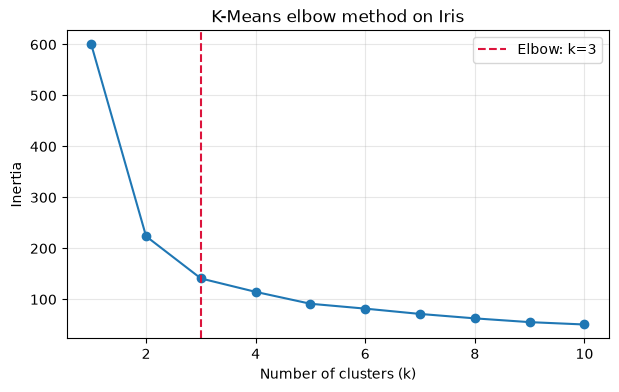

Selected number of clusters: 3


In [10]:
# The elbow is the point farthest from the line joining the endpoints.
# Inspect the plot too: this geometric rule is a guide, not a guarantee.
scaled_inertia = (np.array(inertias) - min(inertias)) / (max(inertias) - min(inertias))
scaled_k = (k_values - k_values[0]) / (k_values[-1] - k_values[0])
distance_to_line = np.abs(scaled_inertia + scaled_k - 1) / np.sqrt(2)
best_k = int(k_values[np.argmax(distance_to_line)])
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.axvline(best_k, color="crimson", linestyle="--", label=f"Elbow: k={best_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means elbow method on Iris")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Selected number of clusters:", best_k)


In [11]:
# Cluster using the selected k and inspect the result.
final_model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
cluster_labels = final_model.fit_predict(X_scaled)
print("Cluster sizes:", pd.Series(cluster_labels).value_counts().sort_index().to_dict())
print(pd.crosstab(iris["Species"], cluster_labels, rownames=["Species"], colnames=["Cluster"]))


Cluster sizes: {0: 53, 1: 50, 2: 47}
Cluster           0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  39   0  11
Iris-virginica   14   0  36


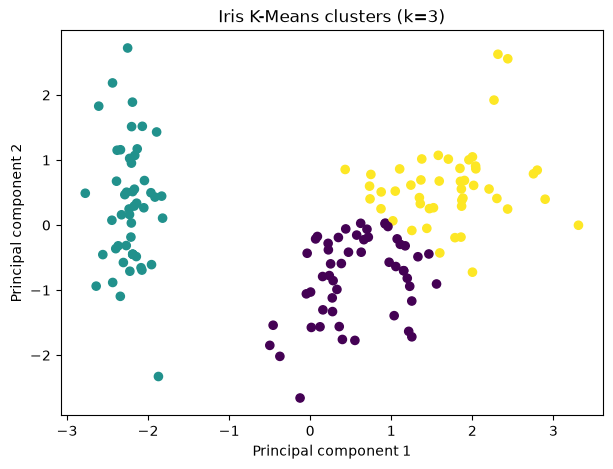

In [12]:
# PCA is used only for a two-dimensional visualization of the clusters.
points_2d = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=cluster_labels, cmap="viridis", s=35)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title(f"Iris K-Means clusters (k={best_k})")
plt.show()
